In [32]:
import json
import random
from pathlib import Path

import numpy as np
import torch
from torch import nn
from torch.utils.data import Dataset, DataLoader
from PIL import Image
import matplotlib.pyplot as plt


torch.manual_seed(0)
random.seed(0)

if torch.cuda.is_available():
    device = "cuda"
elif torch.backends.mps.is_available():
    device = "mps"
else:
    device = "cpu"
print("Using device:", device)

Using device: cuda


In [33]:
from sklearn.model_selection import train_test_split

images_path = Path("dataset/images")
data = json.loads(Path("dataset/gt_public.json").read_text())

image_ids = list(data.keys())
train_ids, rest_ids = train_test_split(image_ids, test_size=0.2, random_state=0)
val_ids, test_ids = train_test_split(rest_ids, test_size=0.5, random_state=0)

print(f"Train: {len(train_ids)}, Val: {len(val_ids)}, Test: {len(test_ids)}")


Train: 41470, Val: 5184, Test: 5184


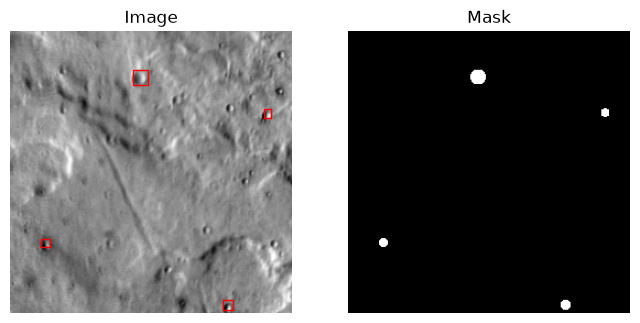

In [34]:
from matplotlib.patches import Rectangle


def make_mask(boxes):
    mask = np.zeros((256, 256), dtype=np.uint8)
    yy, xx = np.mgrid[0:256, 0:256]

    for x, y, w, h in boxes:
        cx = x + w / 2
        cy = y + h / 2
        r = max(w, h) / 2
        inside = (xx + 0.5 - cx) ** 2 + (yy + 0.5 - cy) ** 2 <= r ** 2
        mask[inside] = 1

    return mask


image_id = train_ids[0]
image = plt.imread(images_path / f"{image_id}.png")
mask = make_mask(data[image_id])

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(8, 4))

ax1.imshow(image, cmap="gray")
for x, y, w, h in data[image_id]:
    ax1.add_patch(Rectangle((x, y), w, h, fill=False, edgecolor="red", linewidth=1))
ax1.set_title("Image")
ax1.axis("off")

ax2.imshow(mask, cmap="gray")
ax2.set_title("Mask")
ax2.axis("off")

plt.show()

In [35]:
class CraterDataset(Dataset):
    def __init__(self, image_ids):
        self.image_ids = image_ids

    def __len__(self):
        return len(self.image_ids)

    def __getitem__(self, i):
        image_id = self.image_ids[i]

        image = Image.open(images_path / f"{image_id}.png").convert("L")
        image = torch.tensor(np.array(image), dtype=torch.float32) / 255.0
        image = image.unsqueeze(0)

        mask = make_mask(data[image_id])
        mask = torch.tensor(mask, dtype=torch.float32).unsqueeze(0)

        return image, mask


train_set = CraterDataset(train_ids)
val_set = CraterDataset(val_ids)
test_set = CraterDataset(test_ids)

train_loader = DataLoader(train_set, batch_size=16, shuffle=True)
val_loader = DataLoader(val_set, batch_size=16, shuffle=False)
test_loader = DataLoader(test_set, batch_size=16, shuffle=False)

images, masks = next(iter(train_loader))
print(images.shape)
print(masks.shape)

torch.Size([16, 1, 256, 256])
torch.Size([16, 1, 256, 256])


In [36]:
def conv_block(in_channels, out_channels):
    return nn.Sequential(
        nn.Conv2d(in_channels, out_channels, kernel_size=3, padding=1),
        nn.ReLU(),
        nn.Conv2d(out_channels, out_channels, kernel_size=3, padding=1),
        nn.ReLU(),
    )


class UNet(nn.Module):
    def __init__(self):
        super().__init__()
        self.pool = nn.MaxPool2d(2)

        # shrinking half
        self.down1 = conv_block(1, 32)      # (32, 256, 256)
        self.down2 = conv_block(32, 64)     # (64, 128, 128)
        self.down3 = conv_block(64, 128)    # (128, 64, 64)
        self.bottom = conv_block(128, 256)  # (256, 32, 32)

        # growing half
        self.up3 = nn.ConvTranspose2d(256, 128, kernel_size=2, stride=2)  # (128, 64, 64)
        self.conv3 = conv_block(256, 128)
        self.up2 = nn.ConvTranspose2d(128, 64, kernel_size=2, stride=2)   # (64, 128, 128)
        self.conv2 = conv_block(128, 64)
        self.up1 = nn.ConvTranspose2d(64, 32, kernel_size=2, stride=2)    # (32, 256, 256)
        self.conv1 = conv_block(64, 32)

        self.out = nn.Conv2d(32, 1, kernel_size=1)  # (1, 256, 256)

    def forward(self, x):
        d1 = self.down1(x)
        d2 = self.down2(self.pool(d1))
        d3 = self.down3(self.pool(d2))
        b = self.bottom(self.pool(d3))

        u3 = self.conv3(torch.cat([self.up3(b), d3], dim=1))
        u2 = self.conv2(torch.cat([self.up2(u3), d2], dim=1))
        u1 = self.conv1(torch.cat([self.up1(u2), d1], dim=1))
        return self.out(u1)

model = UNet().to(device)
print(sum(p.numel() for p in model.parameters()))

with torch.no_grad():
    out = model(images.to(device))
print(out.shape)

1925025
torch.Size([16, 1, 256, 256])


In [37]:
run_name = "02-cosine-lr-15epochs"
run_dir = Path("src/unet") / run_name
run_dir.mkdir(parents=True, exist_ok=True)

model = UNet().to(device)
loss_fn = nn.BCEWithLogitsLoss(pos_weight=torch.tensor([10.0], device=device))
optimizer = torch.optim.Adam(model.parameters(), lr=1e-3)

epochs = 15
scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=epochs)

In [38]:
cutoffs = [0.5, 0.6, 0.7, 0.8, 0.9]


def evaluate(model, loader):
    model.eval()
    total_loss, n = 0.0, 0
    intersection = {c: 0 for c in cutoffs}
    union = {c: 0 for c in cutoffs}

    with torch.no_grad():
        for images, masks in loader:
            images, masks = images.to(device), masks.to(device)

            outputs = model(images)
            total_loss += loss_fn(outputs, masks).item() * len(images)
            n += len(images)

            probs = torch.sigmoid(outputs)
            for c in cutoffs:
                preds = (probs > c).float()
                intersection[c] += (preds * masks).sum().item()
                union[c] += ((preds + masks) > 0).sum().item()

    ious = {c: intersection[c] / union[c] for c in cutoffs}
    best_cutoff = max(ious, key=ious.get)
    return total_loss / n, ious[best_cutoff], best_cutoff

In [39]:
history = {"train_loss": [], "val_loss": [], "val_iou": [], "best_cutoff": [], "lr": []}
best_iou = 0.0

for epoch in range(epochs):
    model.train()
    running_loss, n = 0.0, 0
    start = time.time()

    progress = tqdm(train_loader, desc=f"Epoch {epoch + 1}/{epochs}")
    for images, masks in progress:
        images, masks = images.to(device), masks.to(device)

        outputs = model(images)
        loss = loss_fn(outputs, masks)

        optimizer.zero_grad()
        loss.backward()
        optimizer.step()

        running_loss += loss.item() * len(images)
        n += len(images)
        progress.set_postfix(loss=f"{running_loss / n:.4f}")

    train_loss = running_loss / n
    val_loss, val_iou, cutoff = evaluate(model, val_loader)
    lr = optimizer.param_groups[0]["lr"]
    scheduler.step()

    history["train_loss"].append(train_loss)
    history["val_loss"].append(val_loss)
    history["val_iou"].append(val_iou)
    history["best_cutoff"].append(cutoff)
    history["lr"].append(lr)
    (run_dir / "history.json").write_text(json.dumps(history))

    saved = ""
    if val_iou > best_iou:
        best_iou = val_iou
        torch.save(model.state_dict(), run_dir / "unet.pt")
        saved = " (saved)"

    print(f"Epoch {epoch + 1}: train loss {train_loss:.4f} | val loss {val_loss:.4f}, "
          f"val IoU {val_iou:.4f} at cutoff {cutoff} | lr {lr:.6f} | {time.time() - start:.0f}s{saved}")

Epoch 1/15: 100%|██████████| 2592/2592 [02:32<00:00, 17.05it/s, loss=0.4475]


Epoch 1: train loss 0.4475 | val loss 0.3796, val IoU 0.3284 at cutoff 0.8 | lr 0.001000 | 164s (saved)


Epoch 2/15: 100%|██████████| 2592/2592 [02:25<00:00, 17.80it/s, loss=0.3213]


Epoch 2: train loss 0.3213 | val loss 0.3056, val IoU 0.3996 at cutoff 0.7 | lr 0.000989 | 157s (saved)


Epoch 3/15: 100%|██████████| 2592/2592 [02:25<00:00, 17.80it/s, loss=0.2868]


...

Epoch 13: train loss 0.1629 | val loss 0.2595, val IoU 0.5137 at cutoff 0.8 | lr 0.000095 | 156s


Epoch 14/15: 100%|██████████| 2592/2592 [02:23<00:00, 18.05it/s, loss=0.1550]


Epoch 14: train loss 0.1550 | val loss 0.2660, val IoU 0.5149 at cutoff 0.9 | lr 0.000043 | 155s


Epoch 15/15: 100%|██████████| 2592/2592 [02:23<00:00, 18.06it/s, loss=0.1503]


Epoch 15: train loss 0.1503 | val loss 0.2714, val IoU 0.5179 at cutoff 0.9 | lr 0.000011 | 154s


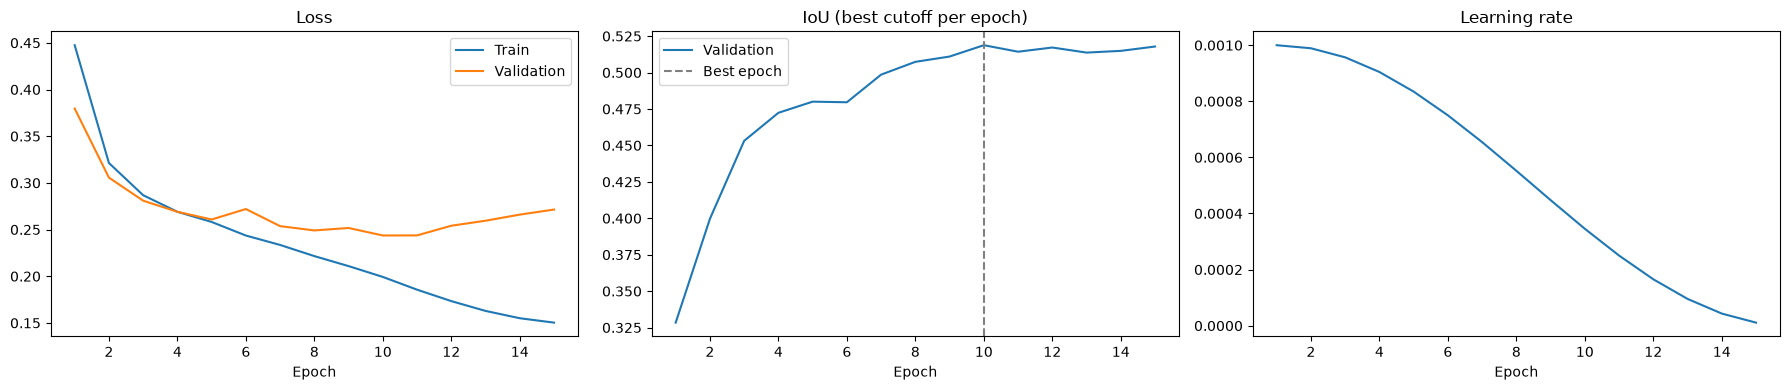

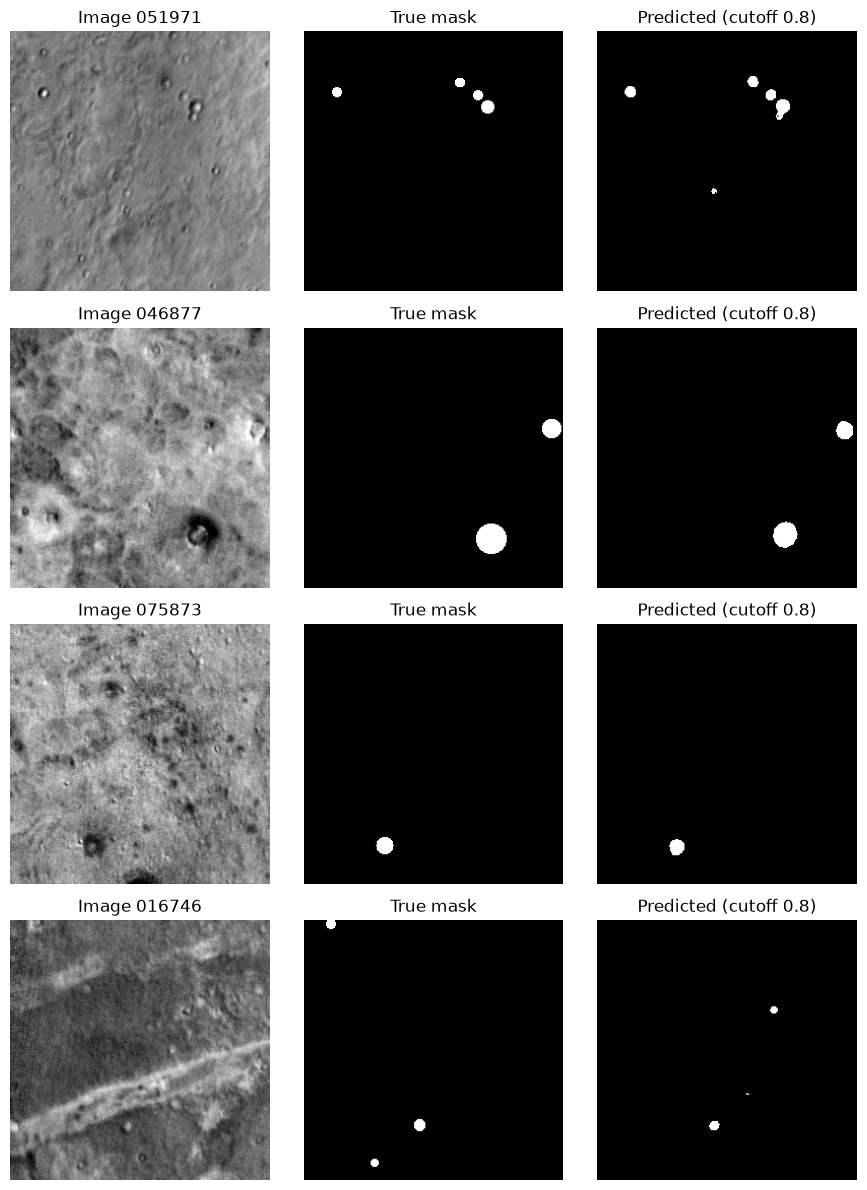

In [40]:
# 1. Notes
best_epoch = history["val_iou"].index(max(history["val_iou"]))
best_cutoff = history["best_cutoff"][best_epoch]

notes = f"""model: UNet (32-64-128-256 channels), 1,925,025 parameters
loss: BCEWithLogitsLoss, pos_weight=10
optimizer: Adam, lr=1e-3, cosine schedule down to 0, no weight decay
batch size: 16
epochs: 15
best epoch: {best_epoch + 1}
best val IoU: {history["val_iou"][best_epoch]:.4f} at cutoff {best_cutoff}
"""
(run_dir / "notes.txt").write_text(notes)

# 2. Loss, IoU, and learning rate curves
epochs_range = range(1, len(history["train_loss"]) + 1)

fig, (ax1, ax2, ax3) = plt.subplots(1, 3, figsize=(18, 4))

ax1.plot(epochs_range, history["train_loss"], label="Train")
ax1.plot(epochs_range, history["val_loss"], label="Validation")
ax1.set_title("Loss")
ax1.set_xlabel("Epoch")
ax1.legend()

ax2.plot(epochs_range, history["val_iou"], label="Validation")
ax2.axvline(best_epoch + 1, linestyle="--", color="gray", label="Best epoch")
ax2.set_title("IoU (best cutoff per epoch)")
ax2.set_xlabel("Epoch")
ax2.legend()

ax3.plot(epochs_range, history["lr"])
ax3.set_title("Learning rate")
ax3.set_xlabel("Epoch")

plt.tight_layout()
plt.savefig(run_dir / "curves.png", dpi=150, bbox_inches="tight")
plt.show()

# 3. Example predictions from the best saved model
model.load_state_dict(torch.load(run_dir / "unet.pt", map_location=device))
model.eval()

fig, axes = plt.subplots(4, 3, figsize=(9, 12))

for i, row in enumerate(axes):
    image, mask = val_set[i]
    with torch.no_grad():
        pred = torch.sigmoid(model(image.unsqueeze(0).to(device)))
    pred = (pred > best_cutoff).float().squeeze().cpu()

    row[0].imshow(image.squeeze(), cmap="gray")
    row[0].set_title(f"Image {val_ids[i]}")
    row[1].imshow(mask.squeeze(), cmap="gray")
    row[1].set_title("True mask")
    row[2].imshow(pred, cmap="gray")
    row[2].set_title(f"Predicted (cutoff {best_cutoff})")
    for ax in row:
        ax.axis("off")

plt.tight_layout()
plt.savefig(run_dir / "predictions.png", dpi=150, bbox_inches="tight")
plt.show()